In [2]:
import numpy as np
from scipy.io import loadmat
import warnings
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.optimize import curve_fit

In [3]:
!pip install pandas
!pip install resonator_tools

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import root, least_squares
from scipy.special import ellipk
from scipy.constants import mu_0, epsilon_0
from resonator_tools import circuit

In [4]:
import os
os.chdir(r"C:\Users\chowdhf4\.vscode\Tunable-Coupler\TC-Main-003")   # paste your copied path here
print(os.getcwd())
print(os.listdir()) 

C:\Users\chowdhf4\.vscode\Tunable-Coupler\TC-Main-003
['Current_v3.mat', 'f0_guess.mat', 'f0_guess_v2.mat', 'f0_guess_v3.mat', 'f0_guess_v4.mat', 'Freq.mat', 'Freq_s1.mat', 'Freq_s2.mat', 'Freq_s3.mat', 'Freq_v2.mat', 'I1.mat', 'I1_s1.mat', 'I1_s2.mat', 'I1_s3.mat', 'S21_complex_wbg_wtd.mat', 'S21_corr_complex.mat', 'S21_corr_complex_v2.mat', 'S21_mag_s1.mat', 'S21_mag_s2.mat', 'S21_mag_s3.mat', 'S21_phase_s1.mat', 'S21_phase_s2.mat', 'S21_phase_s3.mat', 'TC-Main-003_fit-v1.ipynb', 'TC-Main-003_fit-v2.ipynb']


In [5]:
File_S21_mag_s1     = 'S21_mag_s1.mat'
File_S21_mag_s2     = 'S21_mag_s2.mat'
File_S21_mag_s3     = 'S21_mag_s3.mat'
File_S21_phase_s1   = 'S21_phase_s1.mat'
File_S21_phase_s2   = 'S21_phase_s2.mat'
File_S21_phase_s3   = 'S21_phase_s3.mat'
FILE_FREQ_s1        = 'Freq_s1.mat'
FILE_FREQ_s2        = 'Freq_s2.mat'
FILE_FREQ_s3        = 'Freq_s3.mat'
FILE_CURRENT_s1     = 'I1_s1.mat'
FILE_CURRENT_s2     = 'I1_s2.mat'
FILE_CURRENT_s3     = 'I1_s3.mat'


Mat_Freq_s1     = loadmat(FILE_FREQ_s1, squeeze_me=True)
Mat_Freq_s2     = loadmat(FILE_FREQ_s2, squeeze_me=True)
Mat_Freq_s3     = loadmat(FILE_FREQ_s3, squeeze_me=True)
Mat_Current_s1  = loadmat(FILE_CURRENT_s1, squeeze_me=True)
Mat_Current_s2  = loadmat(FILE_CURRENT_s2, squeeze_me=True)
Mat_Current_s3  = loadmat(FILE_CURRENT_s3, squeeze_me=True)
Mat_mag_s1  = loadmat(File_S21_mag_s1, squeeze_me=True)
Mat_mag_s2  = loadmat(File_S21_mag_s2, squeeze_me=True)
Mat_mag_s3  = loadmat(File_S21_mag_s3, squeeze_me=True)
Mat_phase_s1 = loadmat(File_S21_phase_s1, squeeze_me=True)
Mat_phase_s2 = loadmat(File_S21_phase_s2, squeeze_me=True)
Mat_phase_s3 = loadmat(File_S21_phase_s3, squeeze_me=True)

# Mat_F0_Guess = loadmat(File_F0_Guess, squeeze_me=True)
S21_mag_f1 = Mat_mag_s1['S21_filtered_fit_1'] 
S21_mag_f2 = Mat_mag_s2['S21_filtered_fit_2']
S21_mag_f3 = Mat_mag_s3['S21_filtered_fit_3']
S21_phase_f1 = Mat_phase_s1['S21_filtered_phase_fit_1']
S21_phase_f2 = Mat_phase_s2['S21_filtered_phase_fit_2']
S21_phase_f3 = Mat_phase_s3['S21_filtered_phase_fit_3']
Freq_f1 = Mat_Freq_s1['Freq_filtered_f1']
Freq_f2 = Mat_Freq_s2['Freq_filtered_f2']
Freq_f3 = Mat_Freq_s3['Freq_filtered_f3']
I1_s1  = Mat_Current_s1['I1_s1']
I1_s2  = Mat_Current_s2['I1_s2']
I1_s3  = Mat_Current_s3['I1_s3']
# f0_guess = Mat_F0_Guess['dips']
# Mat_phase_s1
#Mat_Complex
S21_complex_f1 = 10**(S21_mag_f1/20) * np.exp(1j * S21_phase_f1)
S21_complex_f2 = 10**(S21_mag_f2/20) * np.exp(1j * S21_phase_f2)
S21_complex_f3 = 10**(S21_mag_f3/20) * np.exp(1j * S21_phase_f3)
S21_complex_f1.shape[1], S21_complex_f2.shape[1], S21_complex_f3.shape[1]

(40, 23, 38)

In [6]:
fit_results_dict = {}
ports_dict = {}   # optional, if you want to re-plot a specific trace later without refitting
fit_results_dict_2 = {}
ports_dict_2 = {}   # optional, if you want to re-plot a specific trace later without refitting
fit_results_dict_3 = {}
ports_dict_3 = {}   # optional, if you want to re-plot a specific
for i in range(S21_complex_f1.shape[1]):
    f_sub = Freq_f1
    s_sub = S21_complex_f1[:, i]

    port_i = circuit.notch_port(f_sub, s_sub)
    try:
        port_i.autofit(electric_delay=0)
        fit_results_dict[i] = port_i.fitresults
        ports_dict[i] = port_i
    except Exception as e:
        print(f"I1={I1_s1[i]:.3g} mA: fit failed ({e})")
        fit_results_dict[i] = None


for i in range(S21_complex_f2.shape[1]):
    f_sub = Freq_f2
    s_sub = S21_complex_f2[:, i]

    port_i = circuit.notch_port(f_sub, s_sub)
    try:
        port_i.autofit(electric_delay=0)
        fit_results_dict_2[i] = port_i.fitresults
        ports_dict_2[i] = port_i
    except Exception as e:
        print(f"I1={I1_s2[i]:.3g} mA: fit failed ({e})")
        fit_results_dict_2[i] = None

for i in range(S21_complex_f3.shape[1]):
    f_sub = Freq_f3
    s_sub = S21_complex_f3[:, i]

    port_i = circuit.notch_port(f_sub, s_sub)
    try:
        port_i.autofit(electric_delay=0)
        fit_results_dict_3[i] = port_i.fitresults
        ports_dict_3[i] = port_i
    except Exception as e:
        print(f"I1={I1_s3[i]:.3g} mA: fit failed ({e})")
        fit_results_dict_3[i] = None

C:\Users\chowdhf4\AppData\Roaming\Python\Python312\site-packages\resonator_tools\circlefit.py:130: RuntimeWarning: Number of calls to function has reached maxfev = 600.
  p_final = spopt.leastsq(
C:\Users\chowdhf4\AppData\Roaming\Python\Python312\site-packages\resonator_tools\circlefit.py:157: RuntimeWarning: Number of calls to function has reached maxfev = 800.
  p_final = spopt.leastsq(
C:\Users\chowdhf4\AppData\Roaming\Python\Python312\site-packages\resonator_tools\circuit.py:685: RuntimeWarning: invalid value encountered in sqrt
  errors = np.sqrt(np.diagonal(cov))


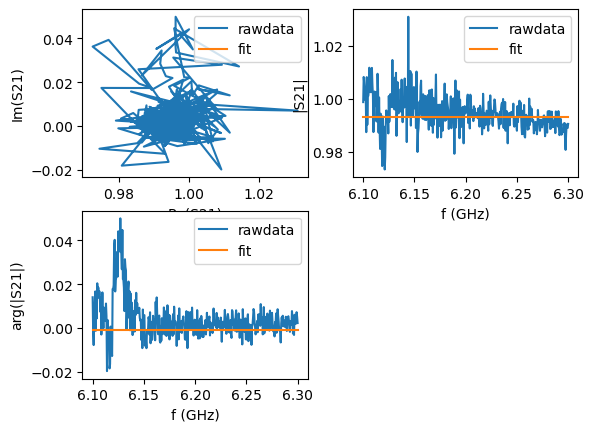

0
I1=1.44 mA: f0=-471651771760.279907 Hz, Ql=3.75e+11


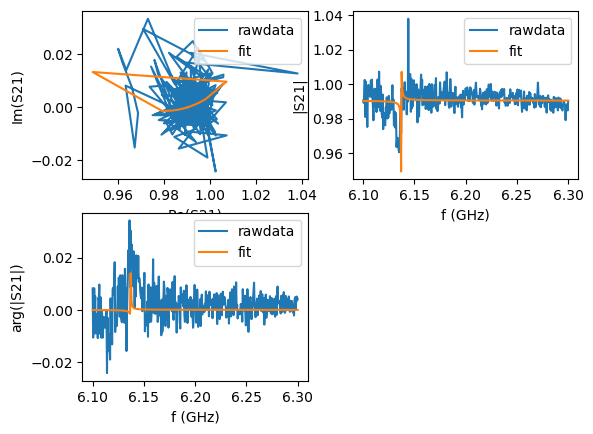

1
I1=1.56 mA: f0=6137138311.094398 Hz, Ql=3.35e+04


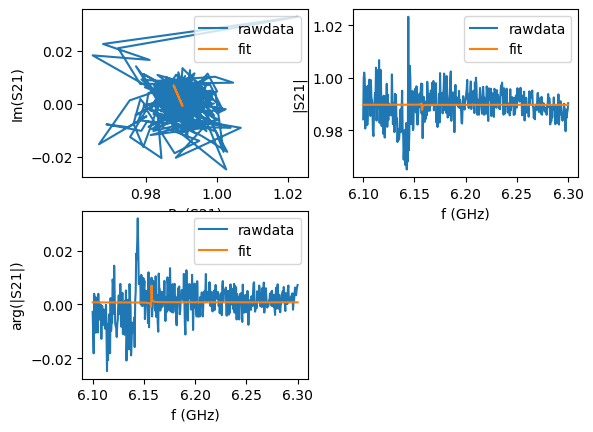

2
I1=1.68 mA: f0=6157393858.417893 Hz, Ql=5.94e+07


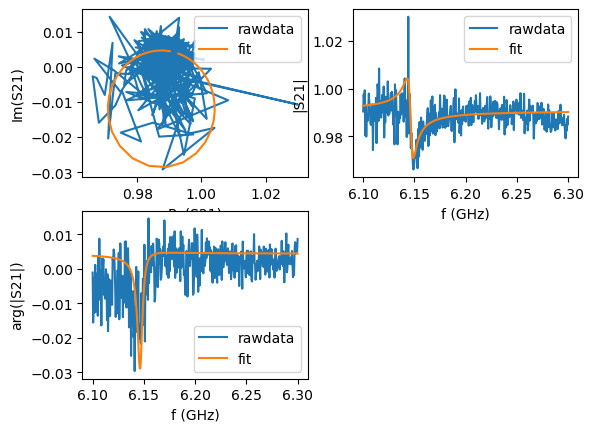

3
I1=1.8 mA: f0=6146443273.669371 Hz, Ql=1.04e+03


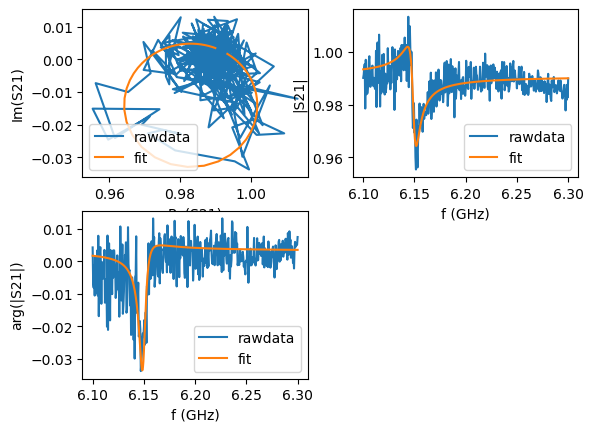

4
I1=1.92 mA: f0=6149237201.748262 Hz, Ql=810


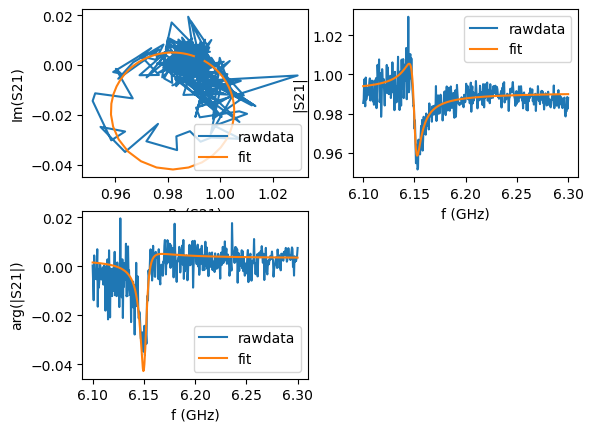

5
I1=2.04 mA: f0=6150255025.322984 Hz, Ql=846


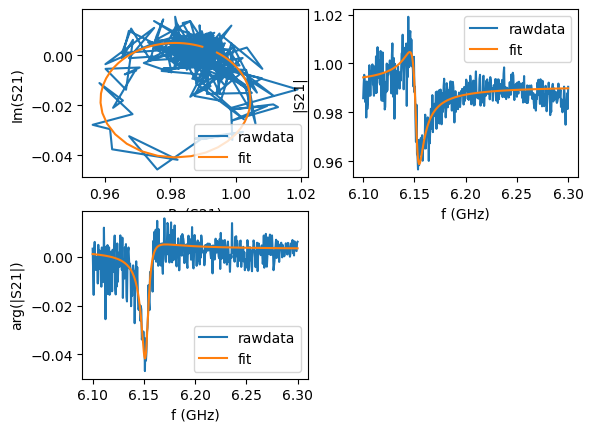

6
I1=2.16 mA: f0=6151899440.082422 Hz, Ql=725


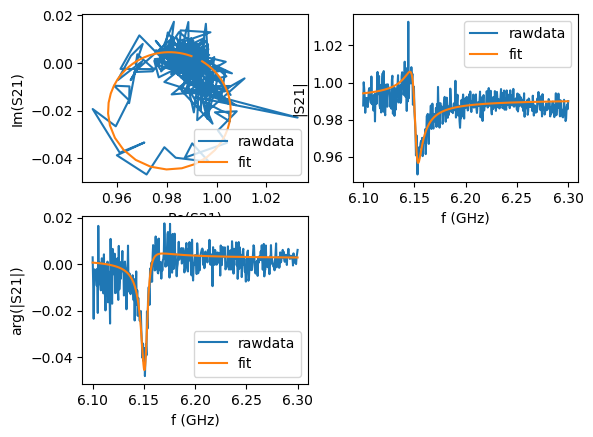

7
I1=2.28 mA: f0=6151201199.586691 Hz, Ql=827


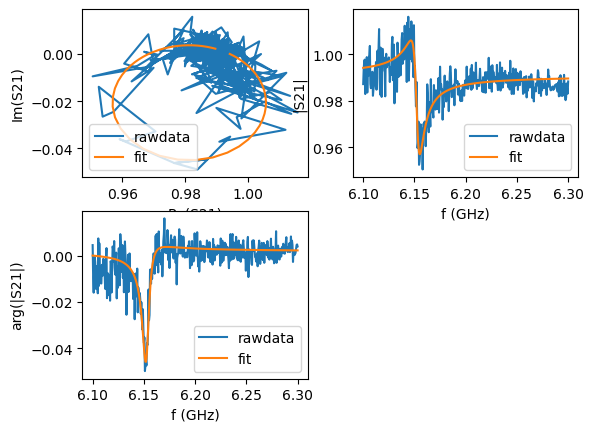

8
I1=2.4 mA: f0=6152512177.326595 Hz, Ql=760


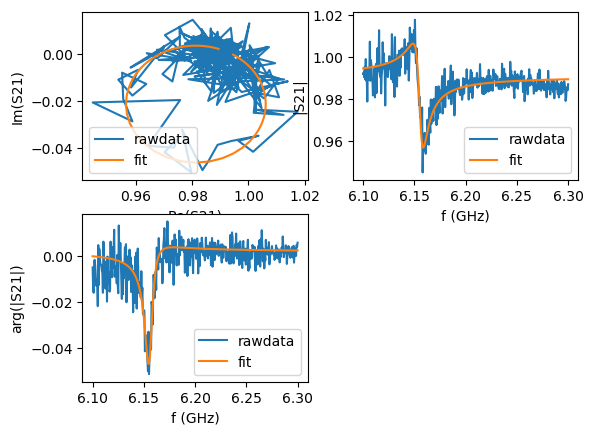

9
I1=2.52 mA: f0=6155424059.598882 Hz, Ql=662


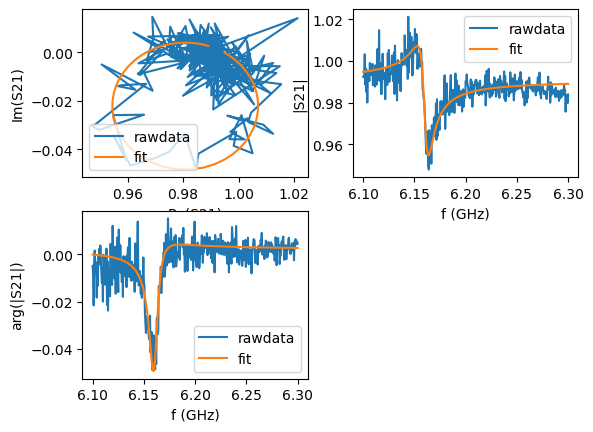

10
I1=2.64 mA: f0=6160234966.701848 Hz, Ql=597


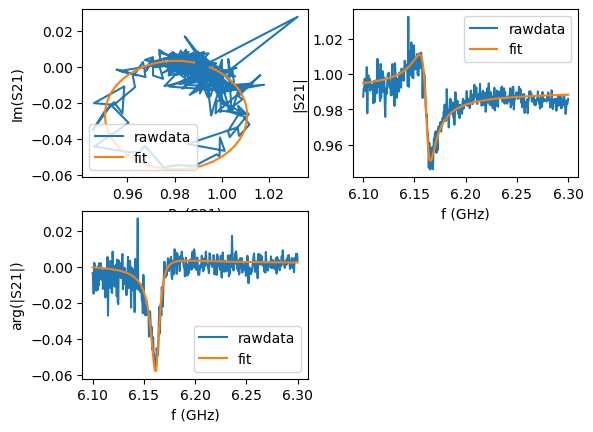

11
I1=2.76 mA: f0=6161906443.091745 Hz, Ql=608


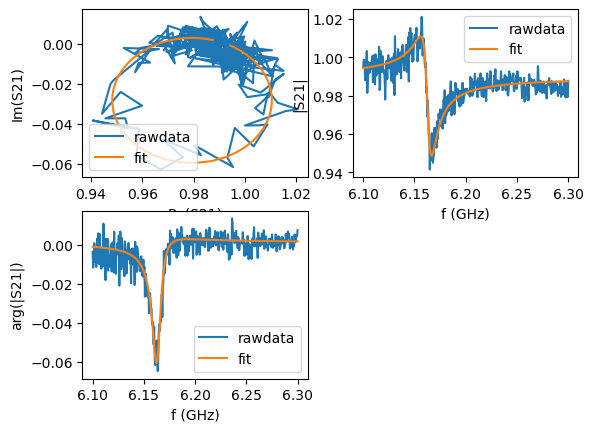

12
I1=2.88 mA: f0=6163044326.866453 Hz, Ql=599


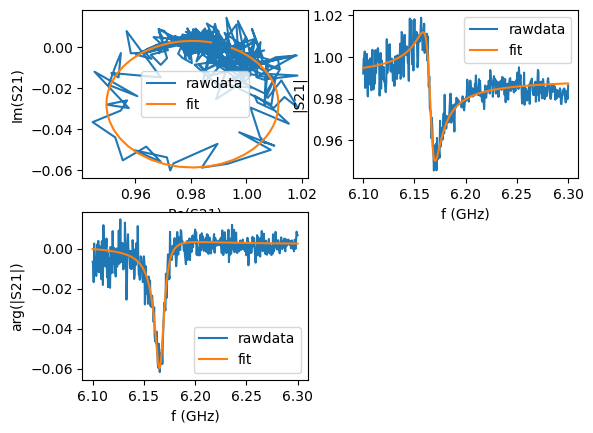

13
I1=3 mA: f0=6165917694.996121 Hz, Ql=541


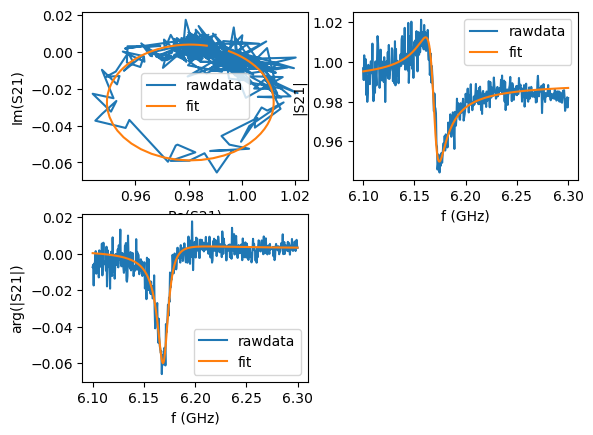

14
I1=3.12 mA: f0=6169403640.161382 Hz, Ql=479


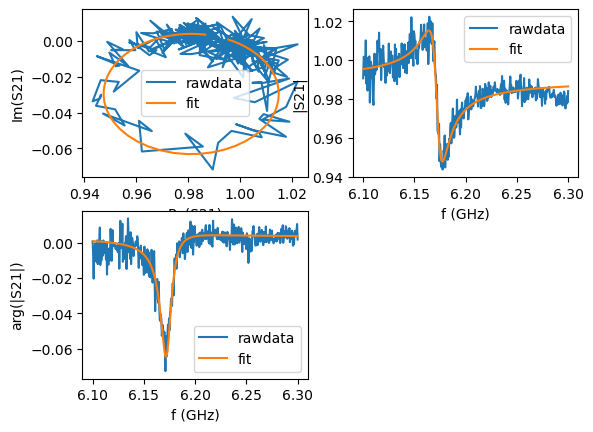

15
I1=3.24 mA: f0=6172190642.555835 Hz, Ql=477


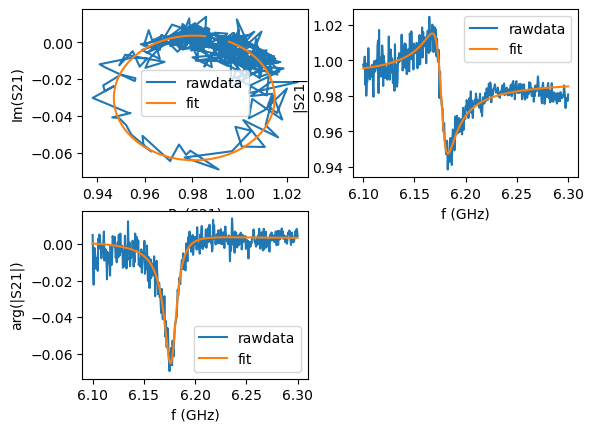

16
I1=3.36 mA: f0=6176713515.572498 Hz, Ql=414


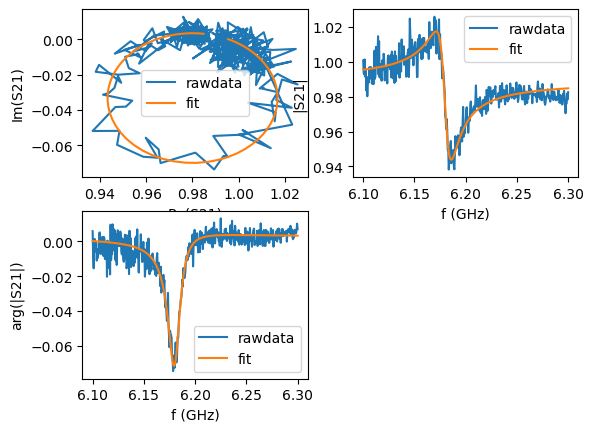

17
I1=3.48 mA: f0=6180104022.371619 Hz, Ql=424


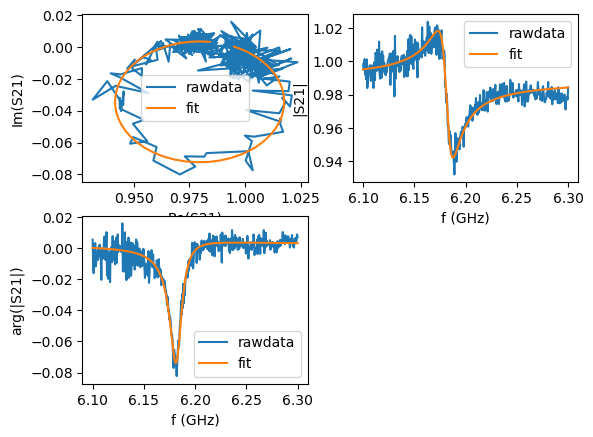

18
I1=3.6 mA: f0=6181789020.795902 Hz, Ql=427


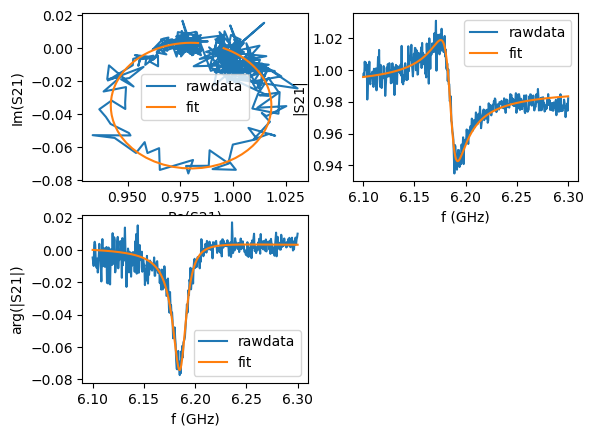

19
I1=3.72 mA: f0=6185496182.574579 Hz, Ql=381


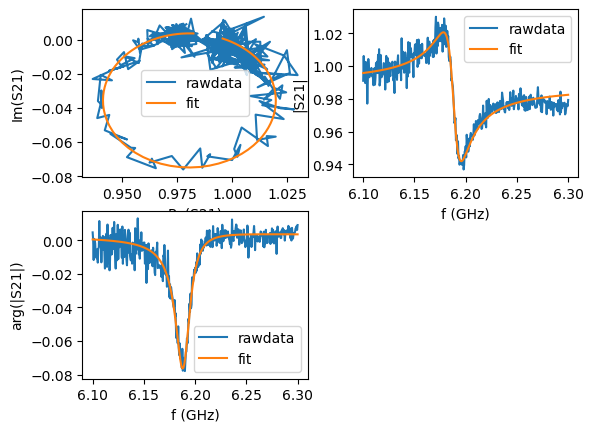

20
I1=3.84 mA: f0=6188407105.295627 Hz, Ql=359


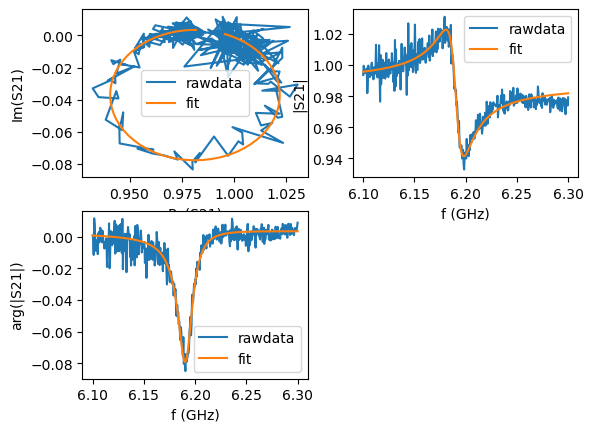

21
I1=3.96 mA: f0=6190630518.647473 Hz, Ql=356


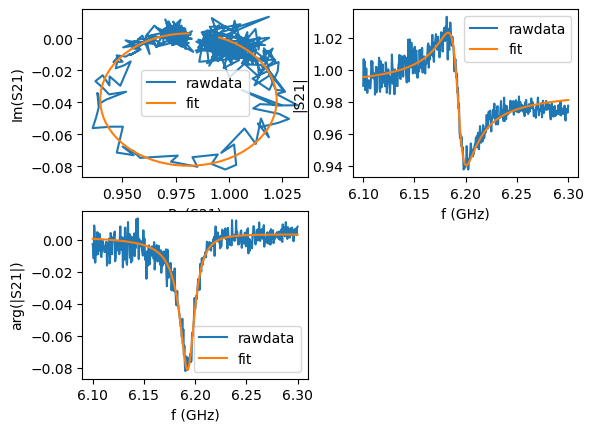

22
I1=4.08 mA: f0=6192906482.048568 Hz, Ql=352


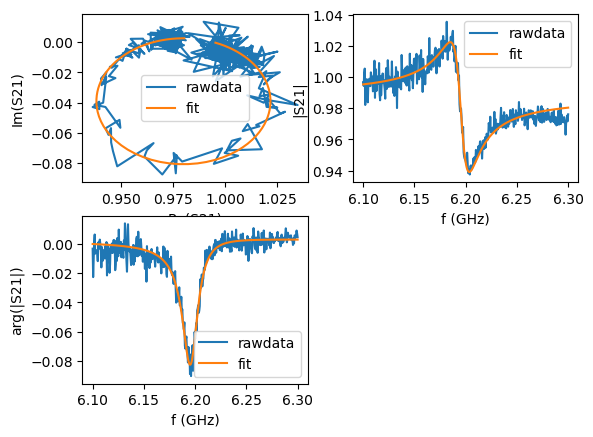

23
I1=4.2 mA: f0=6195608272.845892 Hz, Ql=337


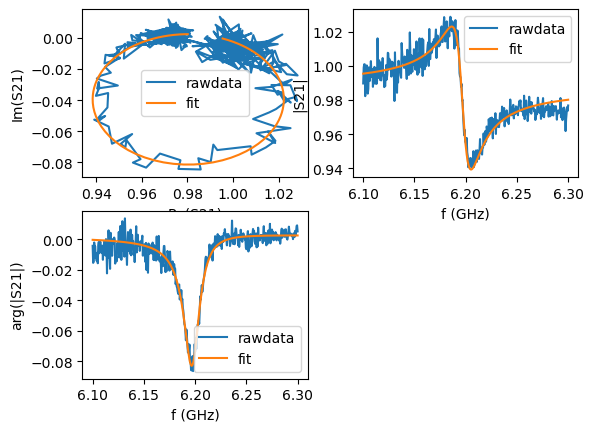

24
I1=4.32 mA: f0=6197099192.189571 Hz, Ql=331


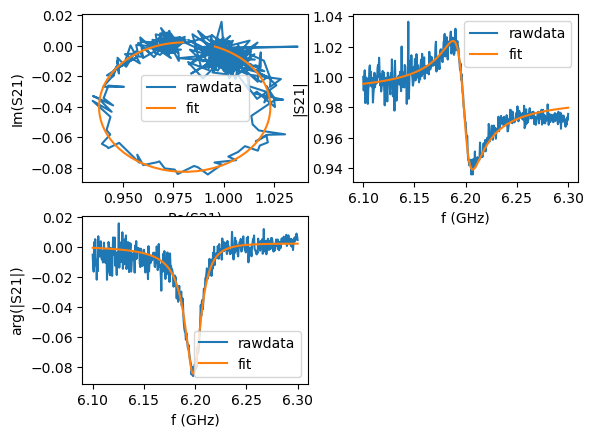

25
I1=4.44 mA: f0=6198479862.886521 Hz, Ql=326


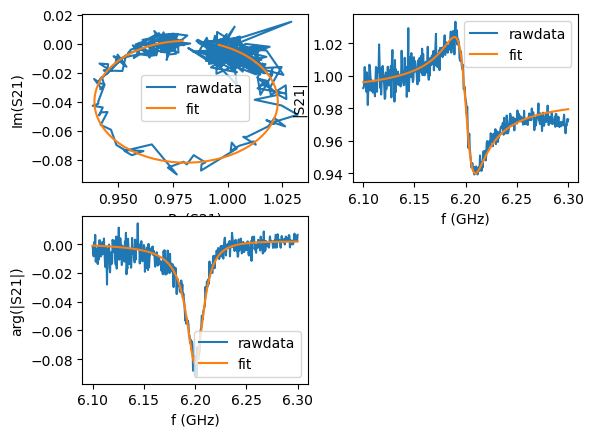

26
I1=4.56 mA: f0=6200501339.784416 Hz, Ql=307


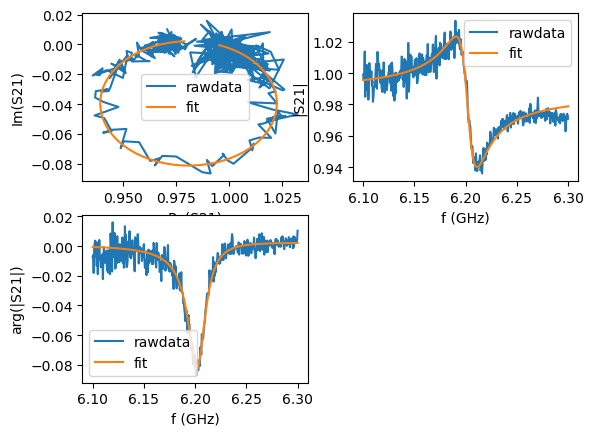

27
I1=4.68 mA: f0=6202011593.885077 Hz, Ql=302


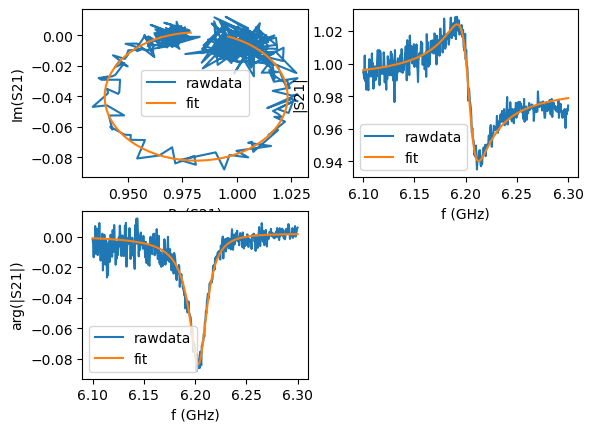

28
I1=4.8 mA: f0=6203469571.005197 Hz, Ql=296


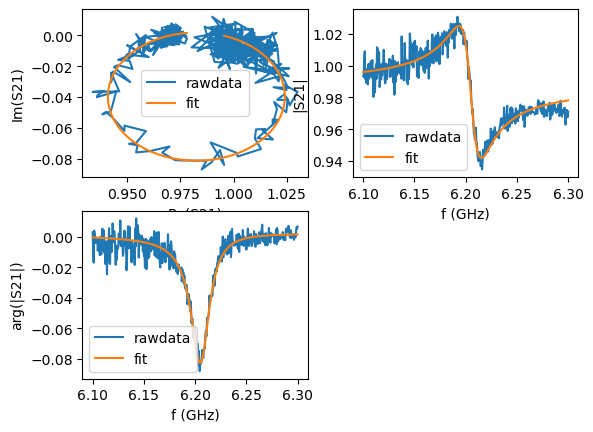

29
I1=4.92 mA: f0=6205204748.891599 Hz, Ql=283


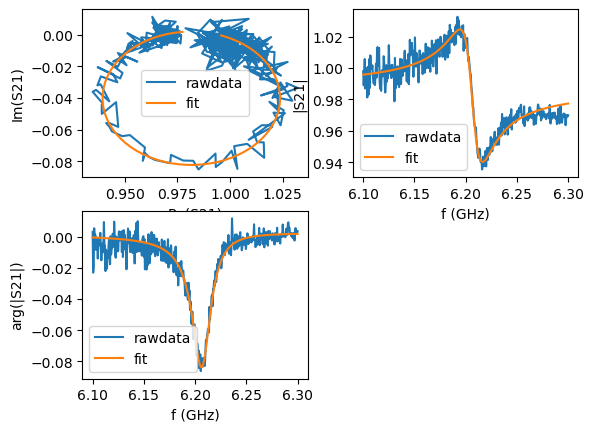

30
I1=5.04 mA: f0=6206477782.860057 Hz, Ql=281


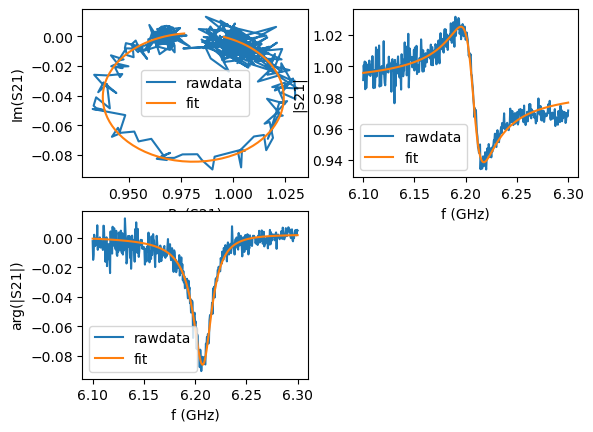

31
I1=5.16 mA: f0=6207602306.970886 Hz, Ql=279


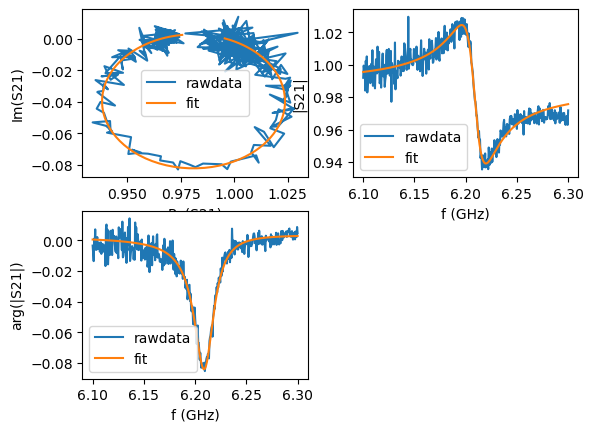

32
I1=5.28 mA: f0=6208997992.016895 Hz, Ql=264


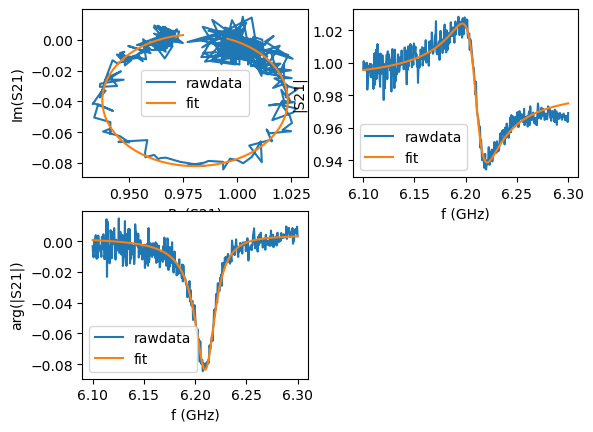

33
I1=5.4 mA: f0=6210045376.911098 Hz, Ql=256


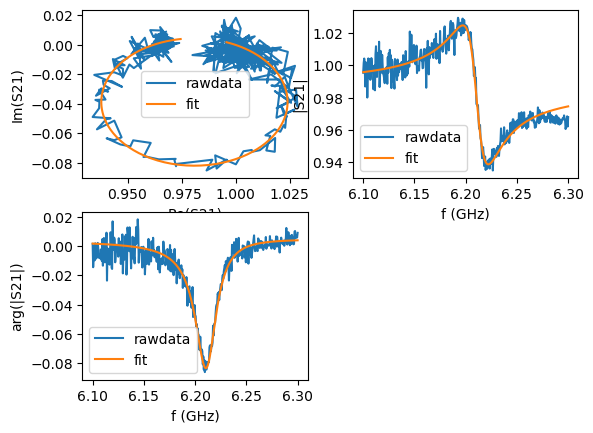

34
I1=5.52 mA: f0=6210747796.980412 Hz, Ql=250


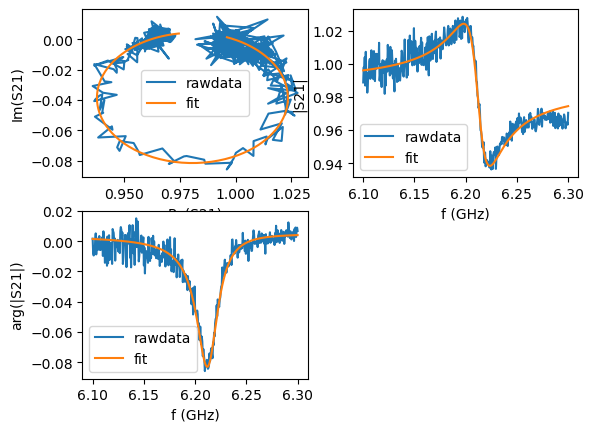

35
I1=5.64 mA: f0=6212200835.091462 Hz, Ql=245


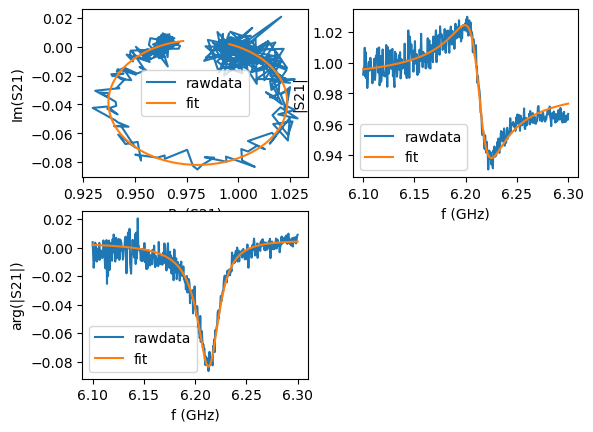

36
I1=5.76 mA: f0=6213338326.975899 Hz, Ql=240


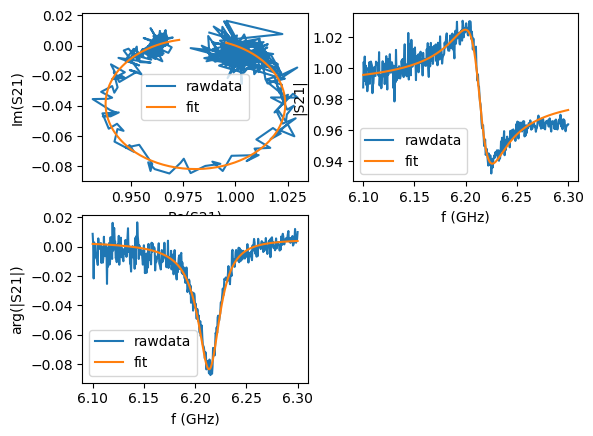

37
I1=5.88 mA: f0=6213866727.046022 Hz, Ql=237


In [12]:
for i in range(S21_complex_f3.shape[1]):
        if fit_results_dict_3[i] is not None:
            ports_dict_3[i].plotall()
            print(i)
            print(f"I1={I1_s3[i]:.3g} mA: f0={fit_results_dict_3[i]['fr']:.6f} Hz, Ql={fit_results_dict_3[i]['Ql']:.3g}")